In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import math
import matplotlib.dates as mdates
import numpy as np

In [2]:
data = pd.read_csv('dane/main data/hydro_klimat_merged_data.csv')

In [3]:
data['Data'] = pd.to_datetime(data['Data'])

In [4]:
data.sort_values(by='Data', inplace=True)

In [5]:
data_ina = data[['Nazwa stacji', 'Data', 'Stan wody [cm]', \
                'Maksymalna temperatura dobowa [°C]', 'Minimalna temperatura dobowa [°C]',\
               'Średnia temperatura dobowa [°C]', 'Temperatura minimalna przy gruncie [°C]', \
                'Suma dobowa opadów nowa [mm]', 'Rodzaj opadu [S/W/]', 'Wysokość pokrywy śnieżnej [cm]',\
                'Nazwa rzeki/jeziora', 'Przepływ [m^3/s]', 'Temperatura wody [st. C]'\
               ]][data['Nazwa rzeki/jeziora'] == 'INA (198)']

data_san = data[['Nazwa stacji', 'Data',  'Stan wody [cm]',\
                'Maksymalna temperatura dobowa [°C]', 'Minimalna temperatura dobowa [°C]',\
               'Średnia temperatura dobowa [°C]', 'Temperatura minimalna przy gruncie [°C]', \
                'Suma dobowa opadów nowa [mm]', 'Rodzaj opadu [S/W/]', 'Wysokość pokrywy śnieżnej [cm]',\
                'Nazwa rzeki/jeziora', 'Przepływ [m^3/s]', 'Temperatura wody [st. C]'\
               ]][data['Nazwa rzeki/jeziora'] == 'SAN (22)'] 

one-hot encoding rodzaj opadu

Zastosowano one-hot encoding na kolumnie ‘Rodzaj opadu’, ponieważ model LSTM wymaga danych liczbowych.

In [6]:
data_ina['Rodzaj opadu [S/W/]'] = data_ina['Rodzaj opadu [S/W/]'].fillna('no_precip')
encoded = pd.get_dummies(data_ina['Rodzaj opadu [S/W/]'], prefix='opad')
data_ina = data_ina.join(encoded)

data_san['Rodzaj opadu [S/W/]'] = data_san['Rodzaj opadu [S/W/]'].fillna('no_precip')
encoded = pd.get_dummies(data_san['Rodzaj opadu [S/W/]'], prefix='opad')
data_san = data_san.join(encoded)

In [7]:
dzien_san = data_san['Data']
suma_opadow_san = data_san['Suma dobowa opadów nowa [mm]']
poziom_wody_san = data_san['Stan wody [cm]']
przeplyw_san = data_san['Przepływ [m^3/s]']
temp_sr_san = data_san['Średnia temperatura dobowa [°C]']
pokr_sn_san = data_san['Wysokość pokrywy śnieżnej [cm]']
temp_min_grunt_san = data_san['Temperatura minimalna przy gruncie [°C]']

Wykres poziom wód w czasie

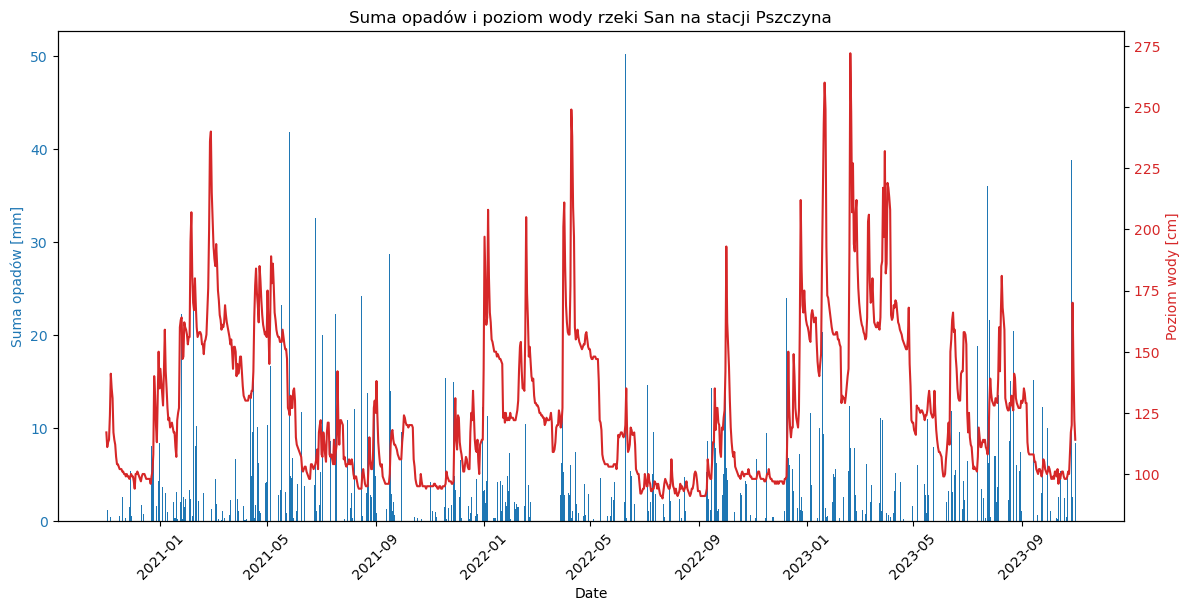

In [8]:
fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:blue'
ax1.set_xlabel('Date')
ax1.set_ylabel('Suma opadów [mm]', color=color)
# ax1.plot(dzien, -suma_opadow_pszcz, color=color)  # Inverse plot for rainfall
ax1.bar(dzien_san, suma_opadow_san, color=color)
ax1.tick_params(axis='y', labelcolor=color)

# #ustawienie osi X
# ax1.xaxis.set_major_locator(mdates.DayLocator(interval=30))  # Show every 7 days
# ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # Format as YYYY-MM-DD
plt.xticks(rotation=45)

ax2 = ax1.twinx()  # Instantiate a second axes that shares the same x-axis
color = 'tab:red'
ax2.set_ylabel('Poziom wody [cm]', color=color)
ax2.plot(dzien_san, poziom_wody_san, color=color)
ax2.tick_params(axis='y', labelcolor=color)

fig.tight_layout()  # To ensure no overlap of y-axis labels
plt.title('Suma opadów i poziom wody rzeki San na stacji Pszczyna')
plt.show()

Wykres za ostatnie 100 dni

In [9]:
data_san_100 = data_san.sort_values(by=['Data'])[-100:]
dzien_san_100 = data_san_100['Data']
suma_opadow_san_100 = data_san_100['Suma dobowa opadów nowa [mm]']
poziom_wody_san_100 = data_san_100['Stan wody [cm]']
przeplyw_san_100 = data_san_100['Przepływ [m^3/s]']
temp_sr_san_100 = data_san_100['Średnia temperatura dobowa [°C]']
pokr_sn_san_100 = data_san_100['Wysokość pokrywy śnieżnej [cm]']
temp_min_grunt_san_100 = data_san_100['Temperatura minimalna przy gruncie [°C]']

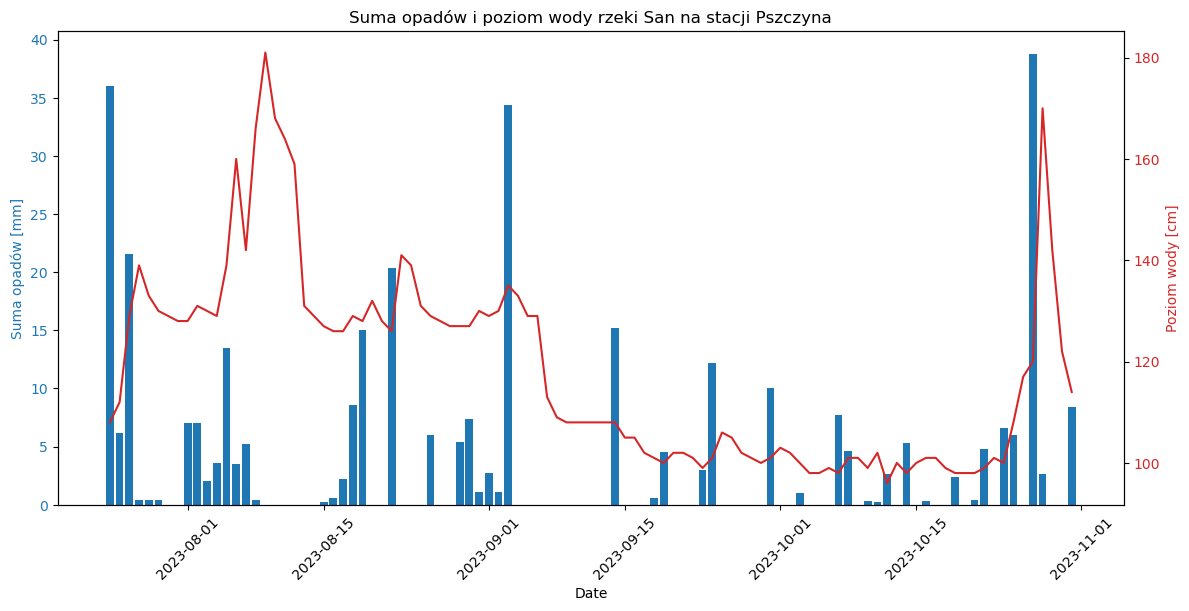

In [10]:
fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:blue'
ax1.set_xlabel('Date')
ax1.set_ylabel('Suma opadów [mm]', color=color)
# ax1.plot(dzien, -suma_opadow_pszcz, color=color)  # Inverse plot for rainfall
ax1.bar(dzien_san_100, suma_opadow_san_100, color=color)
ax1.tick_params(axis='y', labelcolor=color)

# #ustawienie osi X
# ax1.xaxis.set_major_locator(mdates.DayLocator(interval=30))  # Show every 7 days
# ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # Format as YYYY-MM-DD
plt.xticks(rotation=45)

ax2 = ax1.twinx()  # Instantiate a second axes that shares the same x-axis
color = 'tab:red'
ax2.set_ylabel('Poziom wody [cm]', color=color)
ax2.plot(dzien_san_100, poziom_wody_san_100, color=color)
ax2.tick_params(axis='y', labelcolor=color)

fig.tight_layout()  # To ensure no overlap of y-axis labels
plt.title('Suma opadów i poziom wody rzeki San na stacji Pszczyna')
plt.show()

Usunięcie niepotrzebnych kolumn (wartosci nienumeryczne)

In [11]:
data_ina = data_ina.drop(columns=['Data', 'Rodzaj opadu [S/W/]', 'Nazwa rzeki/jeziora', 'Nazwa stacji',\
                                  'Temperatura wody [st. C]'])

data_san = data_san.drop(columns=['Data', 'Rodzaj opadu [S/W/]', 'Nazwa rzeki/jeziora', 'Nazwa stacji', \
                                  'Temperatura wody [st. C]'])


Podział zbioru

Podział na train, valid, test w proporcji 70/15/15

In [12]:
total_samples_san = len(data_san)
train_end_san = int(total_samples_san * 0.7)
validation_end_san = int(total_samples_san * 0.85)

train_san = data_san[:train_end_san]
validation_san = data_san[train_end_san:validation_end_san]
test_san = data_san[validation_end_san:]

In [13]:
print(len(train_san), len(validation_san), len(test_san))

766 164 165


#### Utworzenie sekwencji, aby można było predykować na szeregach czasowych 

In [14]:
def create_sequences(input_data, n_steps, n_ahead=1):
    X, y = [], []
    for i in range(len(input_data) - n_steps - n_ahead + 1):
        #indeks końca sekwencji
        end_ix = i + n_steps
        #Tworzenie sekwencji
        seq_x = input_data[i:end_ix, :]  # cechy i poziom wod w sekwencji wybranej dlugosci
        seq_y = input_data[end_ix+n_ahead-1, 0]  # poziom wód nastepnego dnia (lub nastepnego n_ahead dni dalej) po zakresie w wektorze cech
        X.append(seq_x)
        y.append(seq_y)
    return np.array(X), np.array(y)

Wybór sekwencji

In [15]:
train_san

,Stan wody [cm],Maksymalna temperatura dobowa [°C],Minimalna temperatura dobowa [°C],Średnia temperatura dobowa [°C],Temperatura minimalna przy gruncie [°C],Suma dobowa opadów nowa [mm],Wysokość pokrywy śnieżnej [cm],Przepływ [m^3/s],opad_S,opad_W,opad_no_precip
1278,117,12.3,1.8,4.6,0.6,0.0,0,27.1,0,0,1
1279,111,11.1,0.8,7.1,0.0,1.2,0,21.3,0,1,0
1280,113,13.9,8.4,10.7,6.7,2.0,0,23.1,0,1,0
1281,114,15.2,9.1,11.3,9.0,6.4,0,24.5,0,1,0
1282,124,9.3,2.4,5.2,0.8,0.0,0,34.7,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
2039,97,0.2,-2.2,-1.0,-1.8,0.0,0,12.7,0,1,0
2040,97,4.3,-0.4,1.3,-0.7,0.0,0,12.5,0,0,1
2041,97,1.4,-0.1,0.4,0.1,0.0,0,12.3,0,0,1
2042,96,7.5,-0.1,2.2,-0.2,0.0,0,12.1,0,0,1


In [16]:
#uwaga zmiana typu danych!!
train_san = train_san.to_numpy()
validation_san = validation_san.to_numpy()
test_san = test_san.to_numpy()

In [17]:
n_steps = 10 #długość sekwencji

X_train, y_train = create_sequences(train_san, n_steps=n_steps, n_ahead=1)
X_validation, y_validation = create_sequences(validation_san, n_steps=n_steps, n_ahead=1)
X_test, y_test = create_sequences(test_san, n_steps=n_steps, n_ahead=1)

In [18]:
# y_train

Normalizacja zbioru treningowego

In [19]:
X_train.shape #drugi wymiar to n_steps

(756, 10, 11)

In [20]:
n_train, steps, features = X_train.shape
print(features)
print(X_train.reshape(-1, features).shape)
X_train.reshape(-1, features)

11
(7560, 11)


array([[ 1.17e+02,  1.23e+01,  1.80e+00, ...,  0.00e+00,  0.00e+00,
         1.00e+00],
       [ 1.11e+02,  1.11e+01,  8.00e-01, ...,  0.00e+00,  1.00e+00,
         0.00e+00],
       [ 1.13e+02,  1.39e+01,  8.40e+00, ...,  0.00e+00,  1.00e+00,
         0.00e+00],
       ...,
       [ 9.70e+01,  4.30e+00, -4.00e-01, ...,  0.00e+00,  0.00e+00,
         1.00e+00],
       [ 9.70e+01,  1.40e+00, -1.00e-01, ...,  0.00e+00,  0.00e+00,
         1.00e+00],
       [ 9.60e+01,  7.50e+00, -1.00e-01, ...,  0.00e+00,  0.00e+00,
         1.00e+00]])

In [21]:
from sklearn.preprocessing import StandardScaler

#Zakładamy, że dane mają kształt: (próbki, kroki_czasowe, cechy)
n_train, steps, features = X_train.shape
n_val = X_validation.shape[0]
n_test = X_test.shape[0]

# Przekształcenie do 2D (scalanie kroków czasowych i próbek)
X_train_2d = X_train.reshape(-1, features)
X_val_2d = X_validation.reshape(-1, features)
X_test_2d = X_test.reshape(-1, features)

#Skalowanie
scaler = StandardScaler()
# StandardScaler oblicza średnią i odchylenie tylko z danych treningowych (fit_transform)
X_train_scaled = scaler.fit_transform(X_train_2d) 
#Potem tę samą skalę stosujemy do walidacji i testu (transform) (ochrona przed data_leakage)
X_val_scaled = scaler.transform(X_val_2d)
X_test_scaled = scaler.transform(X_test_2d)

# Przywrócenie oryginalnych kształtów
X_train = X_train_scaled.reshape(n_train, steps, features)
X_validation = X_val_scaled.reshape(n_val, steps, features)
X_test = X_test_scaled.reshape(n_test, steps, features)

In [22]:
X_train.shape

(756, 10, 11)

In [23]:
# mean_train_san = train_san.mean(axis=0)
# train_san -= mean_train_san
# std_san = train_san.std(axis=0)
# train_san /= std_san

In [24]:
#sprawdzenie zmienności zmiennej celu
print(y_train.min(), y_train.max())
print(np.mean(y_train), np.std(y_train))
#zmienność nei jest zbyt duża, dlatego nie skaluję na razie

90.0 249.0
121.80423280423281 28.22919767069173


In [25]:
# #do ewentulanego przetestowania czy poprawi wyniki
# from sklearn.preprocessing import StandardScaler

# y_scaler = StandardScaler()
# y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1, 1))
# y_val_scaled = y_scaler.transform(y_validation.reshape(-1, 1))
# y_test_scaled = y_scaler.transform(y_test.reshape(-1, 1))


Punkt odniesienia (sprawdzenie y_train_san, jaki będzie błąd, gdy przyjmiemy, że poziom jutro będzie taki sam jak dziś)

miara błędu MAE

In [26]:
# np.mean(np.abs(y_validation[-2]-y_validation[-1]))

In [27]:
#czyli na danych nienormalizowanych 
# 0.44248616167015586 * np.std(validation_san[:, 1]) #musi być san bo sprawdam std przed walidacją
# 3.8cm

In [28]:
# validation_san[:, 1]

In [29]:
#na całości, kod z DL Chollet strona 222
def evaluate_naive_method():
    batch_maes = []
    for i, step in enumerate(range(len(y_validation)-1)):
        preds, targets = y_validation[i], y_validation[i+1]
        mae = np.mean(np.abs(preds - targets))
        batch_maes.append(mae)
    return np.mean(batch_maes)
    
print(evaluate_naive_method())
#gdyby patrzeć tylko na dzień poprzedni o ile średnio taki wynik by się mylił (uwaga! miara mae taka jak w modelu!)

8.843137254901961


Płaska sieć z jedną gęstą warstwą (str 494 ML)

In [30]:
X_train.shape[-1]

11

In [31]:
# from keras.models import Sequential
# from keras import layers
# from keras.layers import Flatten, Dense
import keras

model = keras.models.Sequential([
    keras.layers.Flatten(input_shape=[n_steps, X_train.shape[-1]]), #input_shape = (timesteps, features)
    keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mae')

C:\Users\kinga\AppData\Local\anaconda3\lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [32]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    validation_data=(X_validation, y_validation)
)

Epoch 1/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 121.2627 - val_loss: 161.9367
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 119.6186 - val_loss: 161.8732
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 121.1883 - val_loss: 161.8658
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 121.0240 - val_loss: 161.8399
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 120.6029 - val_loss: 161.7896
Epoch 6/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 122.3935 - val_loss: 161.7228
Epoch 7/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 122.1032 - val_loss: 161.6603
Epoch 8/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 121.0539 - val_loss: 161.6763
Epoch 9/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 122.4441 - val_loss: 161.6806
Epoch 10/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 121.6720 - val_loss: 161.6331
Epoch 11/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 120.8101 - val_loss: 161.6551
Epoch 12/20
24/24 ━━━━━━━━━━━

In [33]:
# plt.figure(figsize=(10, 6))
# plt.plot(history.history['loss'], label='Training Loss')
# plt.plot(history.history['val_loss'], label='Validation Loss')
# plt.title('Model Training History')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.legend()
# plt.grid(True)
# plt.show()

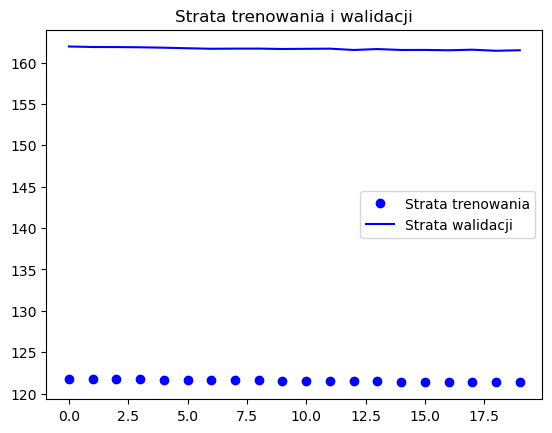

In [34]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

In [35]:
min(val_loss)

161.41806030273438

Prosty model rekurencyjny

In [133]:
X_train.shape

(765, 1, 11)

In [134]:
# X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))

In [36]:
# import keras

model = keras.models.Sequential([
    keras.layers.SimpleRNN(1, input_shape=[None, X_train.shape[2]]) #tutaj daję wartość none, żeby mogła wykryć zalezności czasowe
])

model.compile(optimizer='adam', loss='mae')

C:\Users\kinga\AppData\Local\anaconda3\lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [37]:
history = model.fit(
    X_train, y_train,
    epochs=30,
    validation_data=(X_validation, y_validation)
)

Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 121.3162 - val_loss: 162.3583
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 122.2321 - val_loss: 162.3453
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 121.2931 - val_loss: 162.3367
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 121.8444 - val_loss: 162.3244
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 121.8581 - val_loss: 162.3158
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 122.0262 - val_loss: 162.3043
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 121.0681 - val_loss: 162.2927
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 121.3039 - val_loss: 162.2844
Epoch 9/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 120.9561 - val_loss: 162.2761
Epoch 10/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 121.8820 - val_loss: 162.2637
Epoch 11/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 122.5292 - val_loss: 162.2568
Epoch 12/30
24/24 ━━━━━━━━━━━

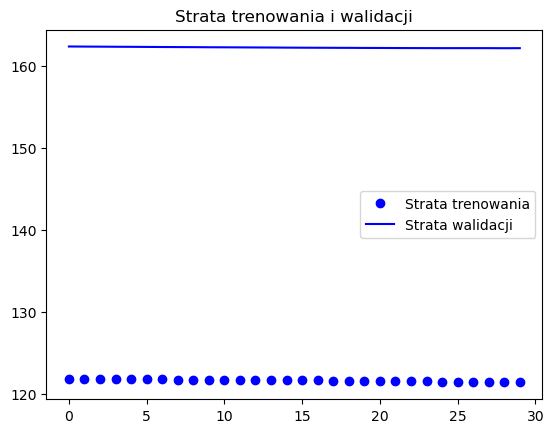

In [38]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

In [39]:
min(val_loss) #źle to wygląda

162.14727783203125

Prosty model LSTM

In [40]:
model = keras.models.Sequential([
    keras.layers.LSTM(64, activation='relu', input_shape=(n_steps, X_train.shape[2])),  # '2' represents the number of features in each time step
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mae')


In [41]:
history = model.fit(
    X_train, y_train,
    epochs=100, #widać, że więcej warstw moze pomóc
    validation_data=(X_validation, y_validation)
)

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 121.0873 - val_loss: 162.0904
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 111.6640 - val_loss: 103.7844
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 45.3129 - val_loss: 65.2451
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 28.3692 - val_loss: 36.6750
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 16.3749 - val_loss: 30.7515
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 12.6786 - val_loss: 25.6279
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 11.0784 - val_loss: 22.3553
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.3529 - val_loss: 24.4319
Epoch 9/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 11.5454 - val_loss: 23.0815
Epoch 10/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 9.5944 - val_loss: 19.7548
Epoch 11/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 8.9839 - val_loss: 18.4316
Epoch 12/100
24/24 ━━━━━━━━━━━━━━━━━━━━

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 4.9761 - val_loss: 13.3534
Epoch 69/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 5.7217 - val_loss: 15.6811
Epoch 70/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 6.1066 - val_loss: 11.7044
Epoch 71/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 5.1910 - val_loss: 14.3570
Epoch 72/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 5.3366 - val_loss: 12.5484
Epoch 73/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 5.5950 - val_loss: 11.6539
Epoch 74/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 5.4581 - val_loss: 11.3277
Epoch 75/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 4.9208 - val_loss: 11.2371
Epoch 76/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 4.5305 - val_loss: 10.6297
Epoch 77/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 4.5191 - val_loss: 11.6586
Epoch 78/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 5.5554 - val_loss: 14.6511
Epoch 79/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - lo

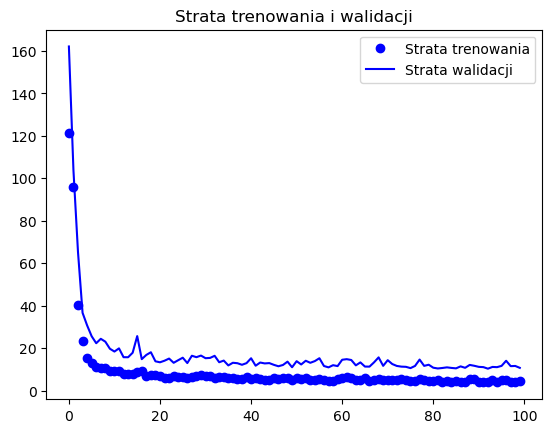

In [42]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

In [43]:
min(val_loss) # o wiele lepiej, ale gorzej niż wartość bazowa

10.36701774597168

Model ze stosem warstw rekurencyjnych

In [44]:
model = keras.models.Sequential([
    keras.layers.LSTM(64, activation='relu', input_shape=(n_steps, X_train.shape[2]),\
                      return_sequences=True),  # warstwa zwraca pełne sekencje wyjściowe (tensory trójwymiarowe)
    keras.layers.LSTM(32, activation='relu', return_sequences=True),
    keras.layers.LSTM(8, activation='relu', return_sequences=True),
    keras.layers.LSTM(16, activation='relu'),
    keras.layers.Dense(4, activation="relu"),
    keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mae')

In [45]:
history = model.fit(
    X_train, y_train,
    epochs=50,
    validation_data=(X_validation, y_validation)
)

Epoch 1/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - loss: 120.4390 - val_loss: 162.6164
Epoch 2/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 122.3142 - val_loss: 161.0669
Epoch 3/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 94.8962 - val_loss: 74.8194
Epoch 4/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 38.1192 - val_loss: 42.1201
Epoch 5/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 19.0797 - val_loss: 33.5563
Epoch 6/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 15.2373 - val_loss: 30.1809
Epoch 7/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 13.4222 - val_loss: 25.9763
Epoch 8/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 11.8009 - val_loss: 25.7805
Epoch 9/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 11.8625 - val_loss: 30.2395
Epoch 10/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 12.1336 - val_loss: 21.3796
Epoch 11/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 11.4547 - val_loss: 23.0042
Epoch 12/50
24/24 ━━━━━━━━━━━━━━━━━━━

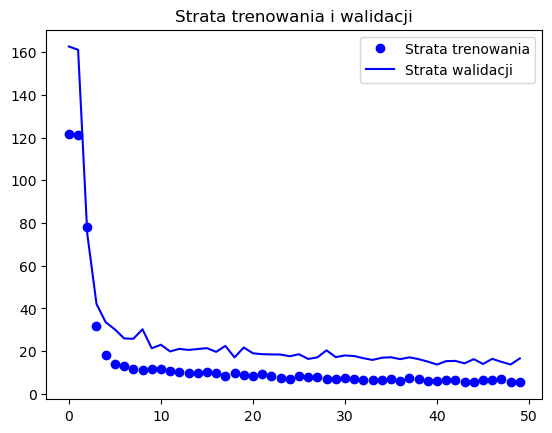

In [46]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

In [47]:
min(val_loss)

13.750055313110352

Lstm ze stosem warstw z mniejszą liczbą neuronów w każdej

In [48]:
model = keras.models.Sequential([
    keras.layers.LSTM(32, activation='relu', input_shape=(n_steps, X_train.shape[2]),\
                      return_sequences=True),  # warstwa zwraca pełne sekencje wyjściowe (tensory trójwymiarowe)
    keras.layers.LSTM(8, activation='relu'),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mae')

In [49]:
history = model.fit(
    X_train, y_train,
    epochs=30,
    validation_data=(X_validation, y_validation)
)

Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 121.4821 - val_loss: 162.6695
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 121.5940 - val_loss: 162.4664
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 121.4602 - val_loss: 137.1608
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 96.7123 - val_loss: 81.0102
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 47.6360 - val_loss: 46.8125
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 21.3696 - val_loss: 36.5884
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 14.7807 - val_loss: 34.3817
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 14.6036 - val_loss: 29.3215
Epoch 9/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 13.0255 - val_loss: 28.5064
Epoch 10/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 11.9038 - val_loss: 26.8532
Epoch 11/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 10.7700 - val_loss: 25.4134
Epoch 12/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 

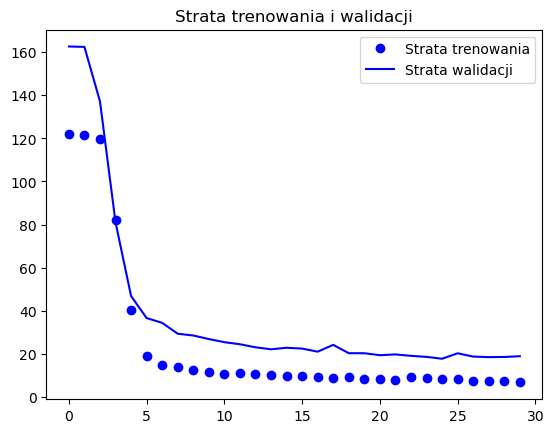

In [50]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

In [51]:
min(val_loss)

17.7128849029541

Lstm ze stosem większej liczby warstw

In [52]:
model = keras.models.Sequential([
    keras.layers.LSTM(64, activation='relu', input_shape=(n_steps, X_train.shape[2]),\
                      return_sequences=True),  # warstwa zwraca pełne sekencje wyjściowe (tensory trójwymiarowe)
    keras.layers.LSTM(32, activation='relu', return_sequences=True),
    keras.layers.LSTM(16, activation='relu', return_sequences=True),
    keras.layers.LSTM(8, activation='relu'),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mae')

In [53]:
history = model.fit(
    X_train, y_train,
    epochs=30,
    validation_data=(X_validation, y_validation)
)

Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - loss: 121.8153 - val_loss: 162.6788
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 120.4649 - val_loss: 162.6362
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 120.9140 - val_loss: 158.5237
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 101.7737 - val_loss: 85.5372
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 36.6703 - val_loss: 56.0898
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 33.8484 - val_loss: 48.0558
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 19.5282 - val_loss: 39.4209
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 16.6066 - val_loss: 32.6830
Epoch 9/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 13.4160 - val_loss: 30.7186
Epoch 10/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 13.1465 - val_loss: 28.5661
Epoch 11/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 12.2762 - val_loss: 25.4673
Epoch 12/30
24/24 ━━━━━━━━━━━━━━━━

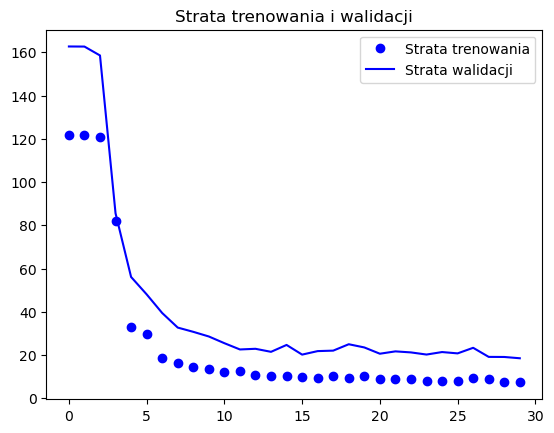

In [54]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

In [55]:
min(val_loss) 

18.496662139892578

Model lstm jak w ML STR  503 (modyfikacja: zmiana na inną funkcję aktywacji, ale tylko w drugiej warstwie lstm)

In [75]:
model = keras.models.Sequential([
    keras.layers.LSTM(32, activation='relu', input_shape=(n_steps, X_train.shape[2]), return_sequences=True),
    keras.layers.LSTM(16, activation='relu'),  # return_sequences=False (domyślnie)
    keras.layers.Dense(1) # keras.layers.TimeDistributed(keras.layers.Dense(1)) dawał by y_predict jako (batch_size, n_steps, 1)
])


model.compile(optimizer='adam', loss='mae')

In [76]:
history = model.fit(
    X_train, y_train,
    epochs=30,
    validation_data=(X_validation, y_validation)
)

Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - loss: 121.1819 - val_loss: 156.1752
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 111.5754 - val_loss: 89.8367
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 59.3646 - val_loss: 45.7085
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 26.2306 - val_loss: 39.3765
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 15.4470 - val_loss: 28.0451
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 12.9741 - val_loss: 26.9815
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 10.5522 - val_loss: 24.0447
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 9.2104 - val_loss: 21.9233
Epoch 9/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 8.8026 - val_loss: 19.9705
Epoch 10/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 8.2992 - val_loss: 21.0292
Epoch 11/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 9.1506 - val_loss: 19.8292
Epoch 12/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/st

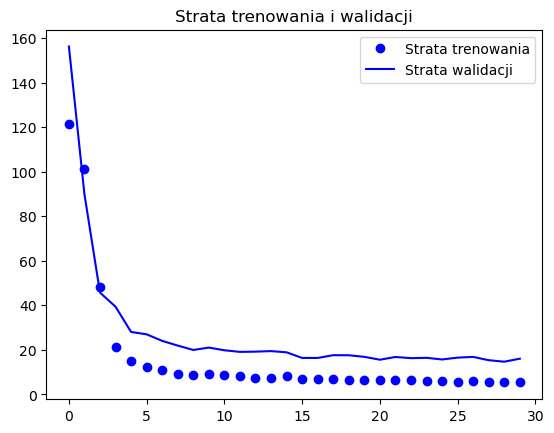

In [77]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

In [78]:
min(val_loss)

14.69109058380127

Actual vs predicted

In [72]:
def plot_predictions_with_error(true_data, predicted_data, title):
    plt.figure(figsize=(10, 12))
    
    # Flatten arrays to ensure compatibility with matplotlib
    true_data_flatten = true_data.flatten()
    predicted_data_flatten = predicted_data.flatten()
    
    # Calculate error
    error = true_data_flatten - predicted_data_flatten
    positive_error_std = np.std(error[error >= 0])
    negative_error_std = np.std(error[error < 0])
    mae = sum(np.abs(error))/len(error)
    print(f"Błąd MAE {mae}")
    # Plot true data vs. predicted data
    ax1 = plt.subplot(2, 1, 1)  # 2 rows, 1 column, 1st subplot
    ax1.plot(true_data_flatten, label='True Data')
    ax1.plot(predicted_data_flatten, label='Predicted Data', alpha=0.7)
    ax1.set_title(title)
    ax1.set_ylabel('Value')
    #ustawienie stałej skali na osi Y, gdy używam oryginalnej skali danych, nie mieszczacej się w zakresie [0,1]
    if true_data[0] > 1:
        ax1 = plt.gca()
        ax1.set_ylim([0, 270]) #San
#         ax1.set_ylim([0, 40]) #Ina
    ax1.legend()

In [73]:
train_pred = model.predict(X_train)
validation_pred = model.predict(X_validation)
test_pred = model.predict(X_test)

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


Training MAE
Błąd MAE 3.623107940431625
Validation MAE
Błąd MAE 14.215130843125381
Test MAE
Błąd MAE 7.8394032139931955


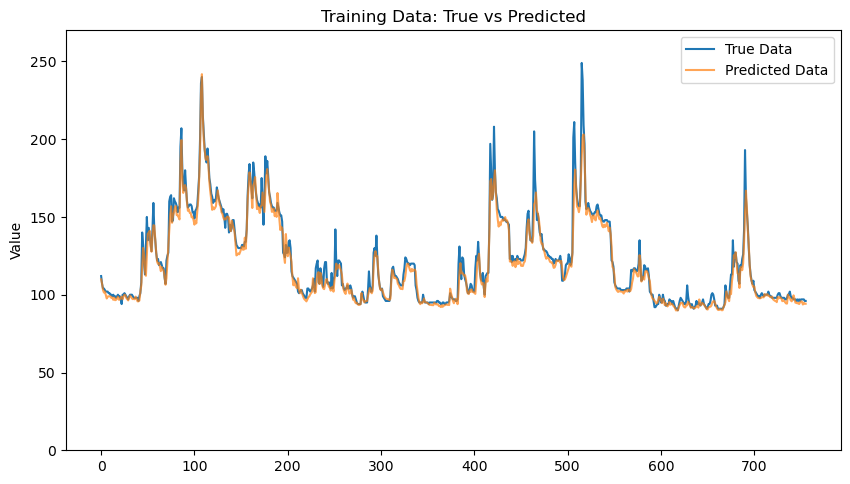

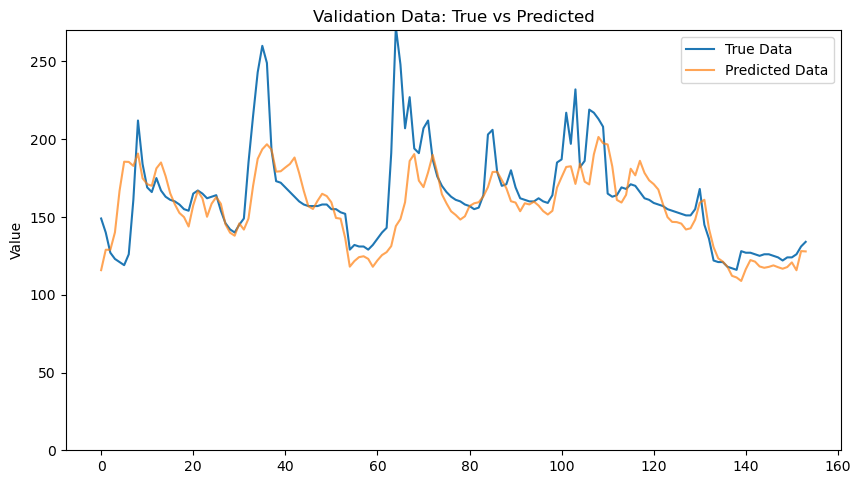

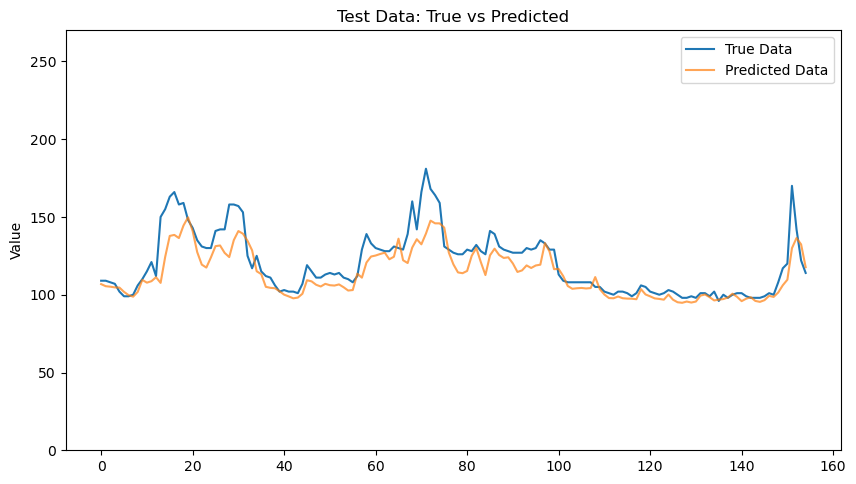

In [74]:
print("Training MAE")
plot_predictions_with_error(y_train, train_pred, 'Training Data: True vs Predicted')
print("Validation MAE")
plot_predictions_with_error(y_validation, validation_pred, 'Validation Data: True vs Predicted')
print("Test MAE")
plot_predictions_with_error(y_test, test_pred, 'Test Data: True vs Predicted')